# IndicHallBench — Publication-Ready Dataset Visualizations

This notebook generates a reproducible set of descriptive figures and data-quality summaries for the final annotation dataset.

**Important:** The notebook does not assume that any particular distribution is desirable. It reports the values present in the CSV. Interpret all plots as descriptive evidence, not as proof of annotation correctness or model superiority.

## Outputs
- High-resolution PNG (600 DPI)
- Vector PDF and SVG
- CSV summary tables
- A data-quality report

Run the notebook from the project root, or update `DATA_PATH` in the next cell.


In [1]:
# 1. Imports and plotting defaults
import os
import re
import json
import ast
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

# Clean, consistent, journal-friendly style
sns.set_theme(style="whitegrid", context="paper", font_scale=1.15)
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 600,
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "axes.titleweight": "bold",
    "axes.labelweight": "regular",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

# EDIT THIS PATH if your CSV is stored elsewhere.
DATA_PATH = Path(
    r"C:/Users/CH.SC.U4CSE23160/Neural Project/IndicHallbench-Hallucinations-Benchmark/data/annotations/final/final_annotations.csv"
)

OUTPUT_DIR = Path("results") / "publication_figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Working directory:", Path.cwd())
print("Data file:", DATA_PATH)
print("Output directory:", OUTPUT_DIR.resolve())


Working directory: C:\Users\CH.SC.U4CSE23160\Neural Project\IndicHallbench-Hallucinations-Benchmark\notebooks
Data file: C:\Users\CH.SC.U4CSE23160\Neural Project\IndicHallbench-Hallucinations-Benchmark\data\annotations\final\final_annotations.csv
Output directory: C:\Users\CH.SC.U4CSE23160\Neural Project\IndicHallbench-Hallucinations-Benchmark\notebooks\results\publication_figures


In [2]:
# 2. Load final annotation dataset
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Cannot find {DATA_PATH}. Update DATA_PATH in Cell 1 to the location of final_annotations.csv."
    )

data = pd.read_csv(DATA_PATH, encoding="utf-8-sig", low_memory=False)
data.columns = [str(c).strip() for c in data.columns]

print(f"Rows: {len(data):,}")
print(f"Columns: {len(data.columns)}")
display(data.head())
display(data.dtypes.astype(str).rename("dtype").to_frame())


Rows: 64,800
Columns: 20


,response_id,question_id,fact_id,language,model_name,timestamp,judge_model,annotation_timestamp,correctness_label,hallucination_types,severity,claims,reason,confidence,review_required,judge_prompt_tokens,judge_output_tokens,annotation_source,annotator_model,human_annotator
0,7dcc63c133de839d15aa,Q_EN_CUL_001,CUL_001,EN,GPT-5.6 Luna,2026-10-07T13:18:23+05:30,llama3.1:8b,2026-11-03T07:58:00.027844+00:00,Correct,"[""None""]",NaN,"[{""claim"": ""Franz Boas"", ""assessment"": ""Suppor...",The question asks for the person who coined th...,0.99,False,3776.0,159.0,llama_judge,llama3.1:8b,NaN
1,bcfa10ff9c06932f320a,Q_EN_CUL_002,CUL_002,EN,GPT-5.6 Luna,2026-10-07T13:18:23+05:30,llama3.1:8b,2026-11-03T07:58:04.471048+00:00,Correct,"[""None""]",NaN,"[{""claim"": ""Cicero"", ""assessment"": ""Supported""...",The question asks for the ancient Roman orator...,0.99,False,3778.0,151.0,llama_judge,llama3.1:8b,NaN
2,e3baa0866d5520e618bf,Q_EN_CUL_003,CUL_003,EN,GPT-5.6 Luna,2026-10-07T13:18:23+05:30,llama3.1:8b,2026-11-03T07:58:08.993632+00:00,Correct,"[""None""]",NaN,"[{""claim"": ""UNESCO"", ""assessment"": ""Supported""...",The question asks for the organization that ad...,0.99,False,3778.0,152.0,llama_judge,llama3.1:8b,NaN
3,ee8f442224fdb3976bac,Q_EN_CUL_004,CUL_004,EN,GPT-5.6 Luna,2026-10-07T13:18:23+05:30,llama3.1:8b,2026-11-03T07:58:13.307810+00:00,Correct,"[""None""]",NaN,"[{""claim"": ""Richard Hoggart"", ""assessment"": ""S...",The question asks for the founder of the Centr...,0.99,False,3770.0,144.0,llama_judge,llama3.1:8b,NaN
4,d245bb05ab71f4311d31,Q_EN_CUL_005,CUL_005,EN,GPT-5.6 Luna,2026-10-07T13:18:23+05:30,llama3.1:8b,2026-11-03T07:58:17.698484+00:00,Correct,"[""None""]",NaN,"[{""claim"": ""Adolf Bastian"", ""assessment"": ""Sup...",The question asks for the entity that argued f...,0.99,False,3772.0,144.0,llama_judge,llama3.1:8b,NaN


,dtype
response_id,object
question_id,object
fact_id,object
language,object
model_name,object
timestamp,object
judge_model,object
annotation_timestamp,object
correctness_label,object
hallucination_types,object


In [3]:
# 3. Resolve column names robustly
# The resolver supports common variants from the annotation pipeline.
def norm_col(x):
    return re.sub(r"[^a-z0-9]+", "", str(x).lower())

COL_LOOKUP = {norm_col(c): c for c in data.columns}

ALIASES = {
    "language": ["language", "lang"],
    "model": ["model_name", "model", "llm", "modelname"],
    "domain": ["domain", "category", "knowledge_domain"],
    "difficulty": ["difficulty", "question_difficulty"],
    "question_type": ["question_type", "questiontype", "query_type"],
    "correctness": ["correctness_label", "correctness", "label", "verdict"],
    "hallucination_type": ["hallucination_types", "hallucination_type", "error_type", "hallucination"],
    "severity": ["severity", "hallucination_severity"],
    "source": ["annotation_source", "annotator_type", "source_type"],
    "confidence": ["confidence", "judge_confidence", "annotation_confidence"],
    "review_required": ["review_required", "needs_review", "manual_review_required"],
    "response": ["response", "model_response", "answer", "generated_answer"],
    "question": ["question", "prompt"],
    "question_id": ["question_id", "qid"],
    "response_id": ["response_id", "id"],
    "annotator_model": ["annotator_model", "judge_model", "judge"],
}

def find_col(key, required=False):
    for alias in ALIASES.get(key, [key]):
        found = COL_LOOKUP.get(norm_col(alias))
        if found is not None:
            return found
    if required:
        raise KeyError(
            f"Required column '{key}' not found. Available columns: {list(data.columns)}"
        )
    return None

COLS = {k: find_col(k) for k in ALIASES}
print("Resolved columns:")
display(pd.DataFrame({"logical_name": list(COLS.keys()),
                      "actual_column": list(COLS.values())}))


Resolved columns:


,logical_name,actual_column
0,language,language
1,model,model_name
2,domain,None
3,difficulty,None
4,question_type,None
5,correctness,correctness_label
6,hallucination_type,hallucination_types
7,severity,severity
8,source,annotation_source
9,confidence,confidence


In [4]:
# 4. Helpers: clean categories, parse list-valued fields, and save figures
def clean_series(series, missing_label="Missing"):
    s = series.copy()
    s = s.astype("string").str.strip()
    s = s.replace({"": pd.NA, "nan": pd.NA, "None": pd.NA, "null": pd.NA})
    return s.fillna(missing_label)

def parse_multi_value(value):
    """Convert list-like CSV cells into a list of labels."""
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return []
    if isinstance(value, (list, tuple, set)):
        vals = list(value)
    else:
        txt = str(value).strip()
        if not txt or txt.lower() in {"nan", "none", "null", "[]"}:
            return []
        vals = None
        for parser in (json.loads, ast.literal_eval):
            try:
                parsed = parser(txt)
                if isinstance(parsed, (list, tuple, set)):
                    vals = list(parsed)
                elif isinstance(parsed, dict):
                    vals = list(parsed.keys())
                else:
                    vals = [parsed]
                break
            except Exception:
                pass
        if vals is None:
            # Handle simple comma/semicolon/pipe separated strings.
            vals = re.split(r"[,;|]", txt)
    result = []
    for item in vals:
        label = str(item).strip()
        if label and label.lower() not in {"nan", "none", "null"}:
            result.append(label)
    return result

def save_figure(fig, stem):
    for ext in ("png", "pdf", "svg"):
        fig.savefig(OUTPUT_DIR / f"{stem}.{ext}",
                    dpi=600, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

def barplot_counts(series, title, xlabel, stem, horizontal=True, top_n=None):
    counts = clean_series(series).value_counts()
    if top_n is not None:
        counts = counts.head(top_n)
    if counts.empty:
        print(f"Skipped {stem}: no data.")
        return
    height = max(4.2, 0.38 * len(counts) + 1.2)
    fig, ax = plt.subplots(figsize=(8.2, height))
    if horizontal:
        sns.barplot(x=counts.values, y=counts.index, ax=ax)
        ax.set_xlabel(xlabel)
        ax.set_ylabel("")
        for i, v in enumerate(counts.values):
            ax.text(v, i, f" {v:,}", va="center", fontsize=9)
    else:
        sns.barplot(x=counts.index, y=counts.values, ax=ax)
        ax.set_ylabel(xlabel)
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=35)
        for i, v in enumerate(counts.values):
            ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
    ax.set_title(title, pad=12)
    fig.tight_layout()
    save_figure(fig, stem)
    return counts


## A. Dataset composition and coverage

These figures describe the benchmark composition. They should be reported before model-performance or hallucination-analysis results.


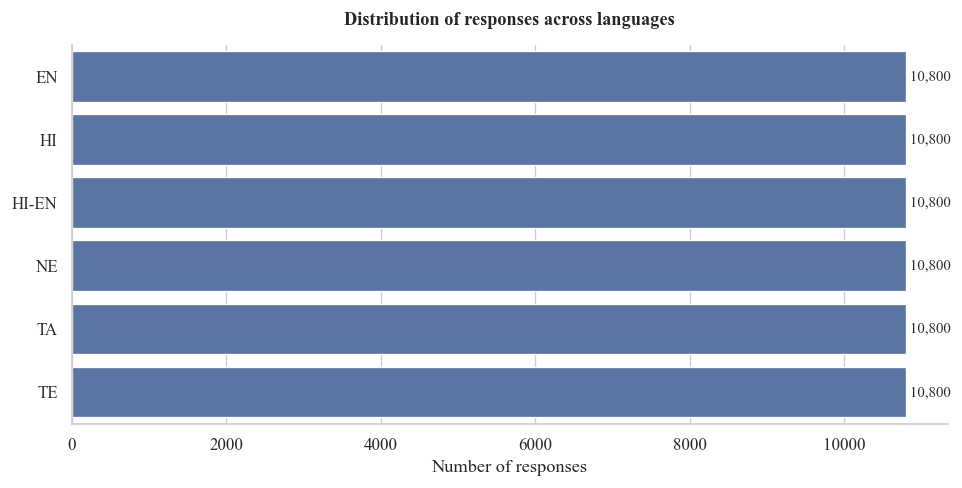

,responses
language,
EN,10800
HI,10800
HI-EN,10800
NE,10800
TA,10800
TE,10800


In [5]:
# 5. Figure 1 — Language distribution
lang_col = COLS["language"]
if lang_col:
    lang_counts = barplot_counts(
        data[lang_col],
        "Distribution of responses across languages",
        "Number of responses",
        "fig01_language_distribution"
    )
    display(lang_counts.rename("responses").to_frame())
else:
    print("Skipped: language column not found.")


In [6]:
# 6. Figure 2 — Domain distribution
domain_col = COLS["domain"]
if domain_col:
    domain_counts = barplot_counts(
        data[domain_col],
        "Distribution of responses across knowledge domains",
        "Number of responses",
        "fig02_domain_distribution"
    )
    display(domain_counts.rename("responses").to_frame())
else:
    print("Skipped: domain column not found.")


Skipped: domain column not found.


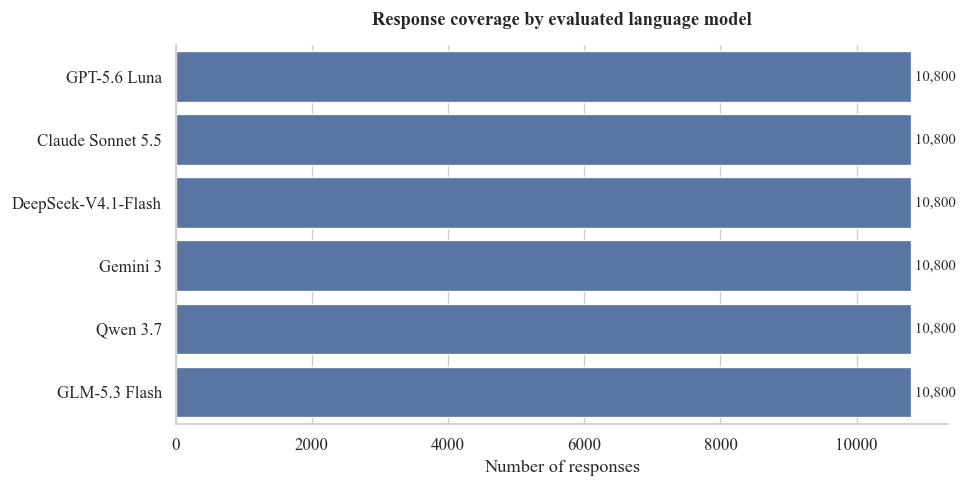

,responses
model_name,
GPT-5.6 Luna,10800
Claude Sonnet 5.5,10800
DeepSeek-V4.1-Flash,10800
Gemini 3,10800
Qwen 3.7,10800
GLM-5.3 Flash,10800


In [7]:
# 7. Figure 3 — LLM/model distribution
model_col = COLS["model"]
if model_col:
    model_counts = barplot_counts(
        data[model_col],
        "Response coverage by evaluated language model",
        "Number of responses",
        "fig03_model_distribution"
    )
    display(model_counts.rename("responses").to_frame())
else:
    print("Skipped: model_name column not found.")


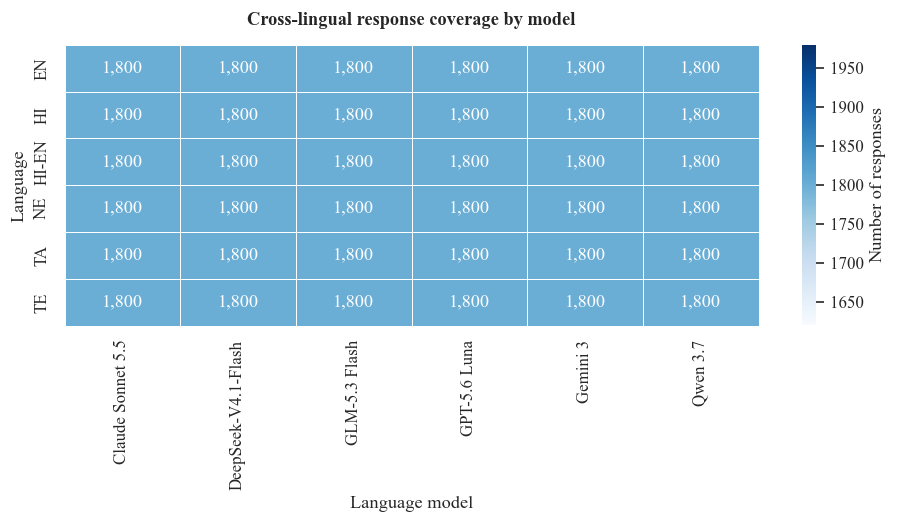

model_name,Claude Sonnet 5.5,DeepSeek-V4.1-Flash,GLM-5.3 Flash,GPT-5.6 Luna,Gemini 3,Qwen 3.7
language,,,,,,
EN,1800,1800,1800,1800,1800,1800
HI,1800,1800,1800,1800,1800,1800
HI-EN,1800,1800,1800,1800,1800,1800
NE,1800,1800,1800,1800,1800,1800
TA,1800,1800,1800,1800,1800,1800
TE,1800,1800,1800,1800,1800,1800


In [8]:
# 8. Figure 4 — Language × model coverage heatmap
if lang_col and model_col:
    coverage = pd.crosstab(
        clean_series(data[lang_col]),
        clean_series(data[model_col])
    )
    fig, ax = plt.subplots(figsize=(max(8, 1.1 * coverage.shape[1]),
                                    max(4.5, 0.65 * coverage.shape[0])))
    sns.heatmap(coverage, annot=True, fmt=",", cmap="Blues",
                linewidths=0.5, cbar_kws={"label": "Number of responses"}, ax=ax)
    ax.set_title("Cross-lingual response coverage by model", pad=12)
    ax.set_xlabel("Language model")
    ax.set_ylabel("Language")
    fig.tight_layout()
    save_figure(fig, "fig04_language_model_coverage")
    display(coverage)
else:
    print("Skipped: language or model column not found.")


In [9]:
# 9. Figure 5 — Difficulty distribution (if present)
difficulty_col = COLS["difficulty"]
if difficulty_col:
    difficulty_counts = barplot_counts(
        data[difficulty_col],
        "Distribution of question difficulty levels",
        "Number of responses",
        "fig05_difficulty_distribution"
    )
    display(difficulty_counts.rename("responses").to_frame())
else:
    print("Skipped: difficulty column not found.")


Skipped: difficulty column not found.


In [10]:
# 10. Figure 6 — Question type distribution (if present)
qtype_col = COLS["question_type"]
if qtype_col:
    qtype_counts = barplot_counts(
        data[qtype_col],
        "Distribution of question types",
        "Number of responses",
        "fig06_question_type_distribution"
    )
    display(qtype_counts.rename("responses").to_frame())
else:
    print("Skipped: question_type column not found.")


Skipped: question_type column not found.


## B. Annotation-label distributions

These figures summarize the labels assigned to responses. If the dataset combines machine and human annotations, use the provenance figures below and report the different annotation processes explicitly.


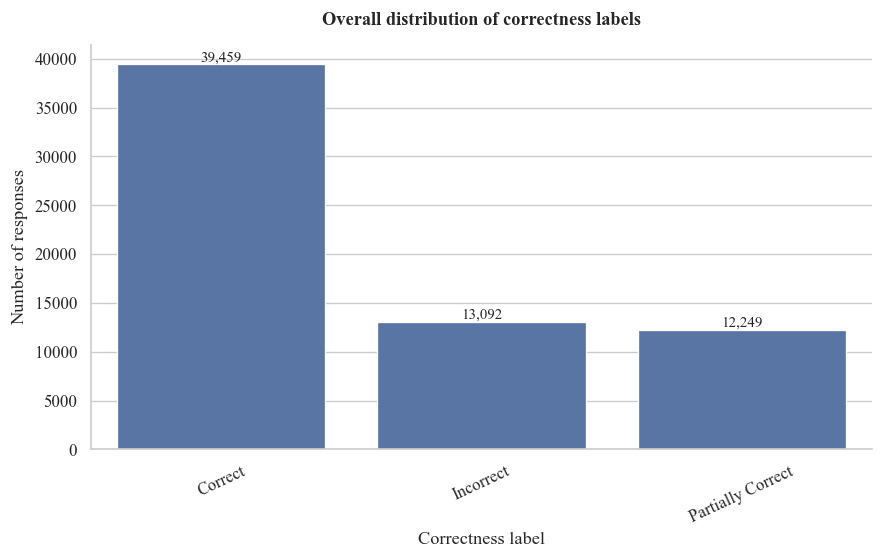

,responses
correctness_label,
Correct,39459
Incorrect,13092
Partially Correct,12249


In [11]:
# 11. Figure 7 — Overall correctness-label distribution
correct_col = COLS["correctness"]
if correct_col:
    correct_counts = clean_series(data[correct_col]).value_counts()
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    sns.barplot(x=correct_counts.index, y=correct_counts.values, ax=ax)
    ax.set_title("Overall distribution of correctness labels", pad=12)
    ax.set_xlabel("Correctness label")
    ax.set_ylabel("Number of responses")
    ax.tick_params(axis="x", rotation=25)
    for i, v in enumerate(correct_counts.values):
        ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
    fig.tight_layout()
    save_figure(fig, "fig07_correctness_distribution")
    display(correct_counts.rename("responses").to_frame())
else:
    print("Skipped: correctness label column not found.")


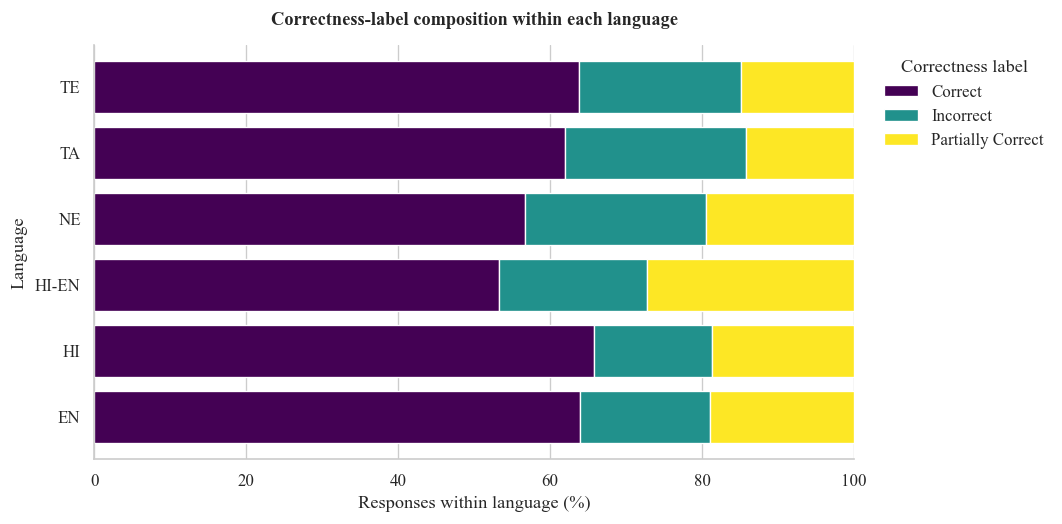

correctness_label,Correct,Incorrect,Partially Correct
language,,,
EN,63.90,17.12,18.98
HI,65.78,15.53,18.69
HI-EN,53.30,19.47,27.23
NE,56.65,23.91,19.44
TA,61.93,23.84,14.23
TE,63.81,21.35,14.83


In [12]:
# 12. Figure 8 — Correctness labels by language (row percentages)
if correct_col and lang_col:
    tmp = pd.crosstab(
        clean_series(data[lang_col]),
        clean_series(data[correct_col]),
        normalize="index"
    ) * 100
    fig, ax = plt.subplots(figsize=(9, max(4.5, 0.7 * len(tmp))))
    tmp.plot(kind="barh", stacked=True, ax=ax, width=0.78,
             colormap="viridis")
    ax.set_title("Correctness-label composition within each language", pad=12)
    ax.set_xlabel("Responses within language (%)")
    ax.set_ylabel("Language")
    ax.set_xlim(0, 100)
    ax.legend(title="Correctness label", bbox_to_anchor=(1.02, 1),
              loc="upper left")
    fig.tight_layout()
    save_figure(fig, "fig08_correctness_by_language")
    display(tmp.round(2))
else:
    print("Skipped: correctness or language column not found.")


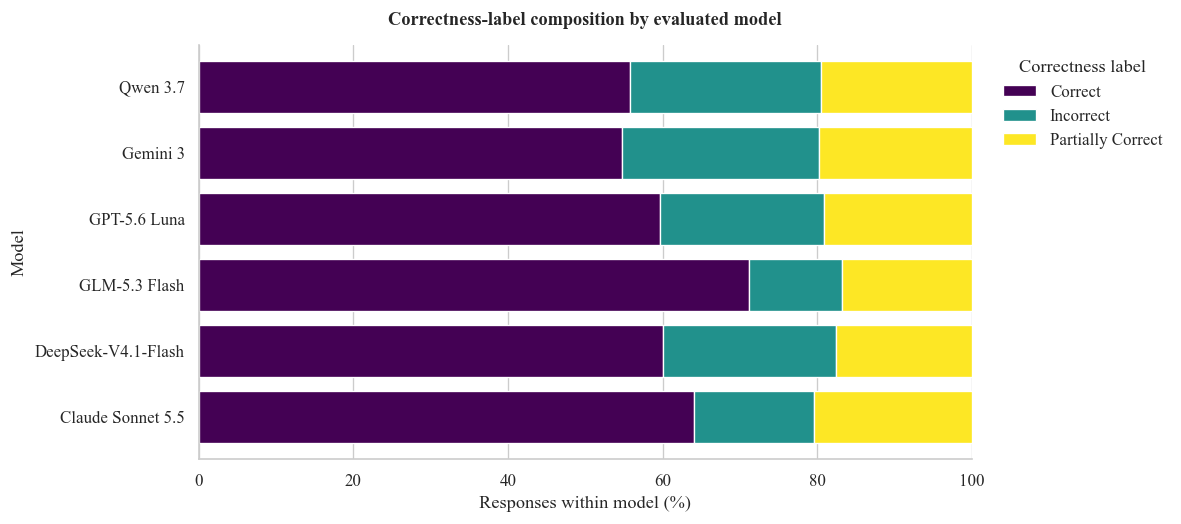

correctness_label,Correct,Incorrect,Partially Correct
model_name,,,
Claude Sonnet 5.5,64.01,15.55,20.44
DeepSeek-V4.1-Flash,60.05,22.37,17.58
GLM-5.3 Flash,71.11,12.02,16.87
GPT-5.6 Luna,59.61,21.28,19.11
Gemini 3,54.81,25.36,19.83
Qwen 3.7,55.78,24.65,19.57


In [13]:
# 13. Figure 9 — Correctness labels by model (row percentages)
if correct_col and model_col:
    tmp = pd.crosstab(
        clean_series(data[model_col]),
        clean_series(data[correct_col]),
        normalize="index"
    ) * 100
    fig, ax = plt.subplots(figsize=(10, max(4.5, 0.55 * len(tmp))))
    tmp.plot(kind="barh", stacked=True, ax=ax, width=0.78,
             colormap="viridis")
    ax.set_title("Correctness-label composition by evaluated model", pad=12)
    ax.set_xlabel("Responses within model (%)")
    ax.set_ylabel("Model")
    ax.set_xlim(0, 100)
    ax.legend(title="Correctness label", bbox_to_anchor=(1.02, 1),
              loc="upper left")
    fig.tight_layout()
    save_figure(fig, "fig09_correctness_by_model")
    display(tmp.round(2))
else:
    print("Skipped: correctness or model column not found.")


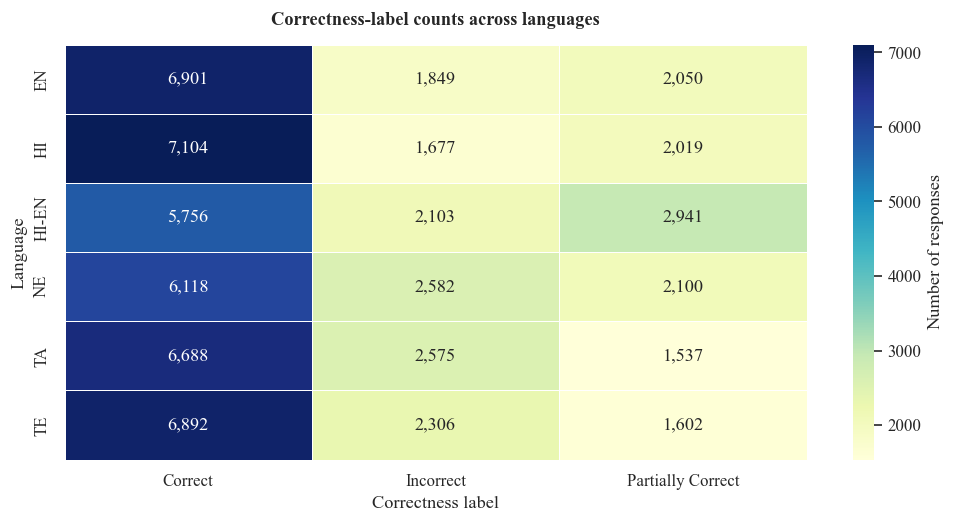

correctness_label,Correct,Incorrect,Partially Correct
language,,,
EN,6901,1849,2050
HI,7104,1677,2019
HI-EN,5756,2103,2941
NE,6118,2582,2100
TA,6688,2575,1537
TE,6892,2306,1602


In [14]:
# 14. Figure 10 — Correctness label × language heatmap (counts)
if correct_col and lang_col:
    tab = pd.crosstab(clean_series(data[lang_col]),
                      clean_series(data[correct_col]))
    fig, ax = plt.subplots(figsize=(8.5, max(4.5, 0.65 * len(tab))))
    sns.heatmap(tab, annot=True, fmt=",", cmap="YlGnBu",
                linewidths=0.5, ax=ax,
                cbar_kws={"label": "Number of responses"})
    ax.set_title("Correctness-label counts across languages", pad=12)
    ax.set_xlabel("Correctness label")
    ax.set_ylabel("Language")
    fig.tight_layout()
    save_figure(fig, "fig10_correctness_language_heatmap")
    display(tab)
else:
    print("Skipped: correctness or language column not found.")


## C. Hallucination taxonomy and severity

For multi-label hallucination annotations, the type counts below are **label incidences**, not mutually exclusive response counts. A single response may contribute to more than one type. The notebook separately reports the number of responses with at least one recorded type.


In [15]:
# 15. Expand multi-label hallucination types
hall_col = COLS["hallucination_type"]
hallucination_long = pd.DataFrame()

if hall_col:
    records = []
    for idx, value in data[hall_col].items():
        labels = parse_multi_value(value)
        for label in labels:
            if label.lower() not in {"none", "no hallucination", "no error"}:
                records.append({"row_index": idx, "hallucination_type": label})
    hallucination_long = pd.DataFrame(records)

    print("Responses with at least one non-None hallucination type:",
          hallucination_long["row_index"].nunique() if not hallucination_long.empty else 0)
    print("Total hallucination-type label incidences:", len(hallucination_long))
else:
    print("Skipped: hallucination type column not found.")


Responses with at least one non-None hallucination type: 15476
Total hallucination-type label incidences: 16085


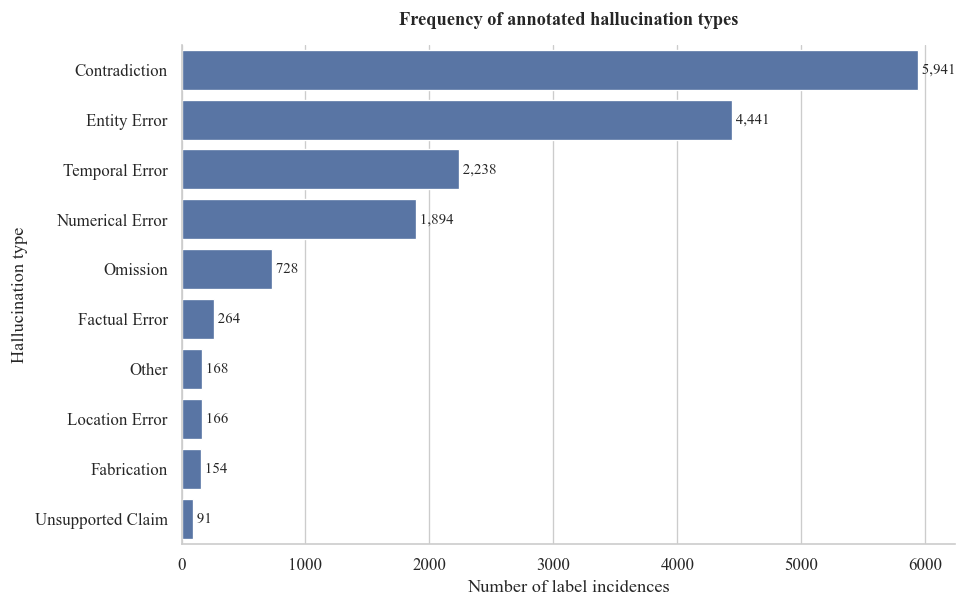

,label_incidences
hallucination_type,
Contradiction,5941
Entity Error,4441
Temporal Error,2238
Numerical Error,1894
Omission,728
Factual Error,264
Other,168
Location Error,166
Fabrication,154


In [16]:
# 16. Figure 11 — Hallucination-type incidence
if not hallucination_long.empty:
    type_counts = hallucination_long["hallucination_type"].value_counts()
    fig, ax = plt.subplots(figsize=(8.2, max(4.5, 0.42 * len(type_counts) + 1)))
    sns.barplot(x=type_counts.values, y=type_counts.index, ax=ax)
    ax.set_title("Frequency of annotated hallucination types", pad=12)
    ax.set_xlabel("Number of label incidences")
    ax.set_ylabel("Hallucination type")
    for i, v in enumerate(type_counts.values):
        ax.text(v, i, f" {v:,}", va="center", fontsize=9)
    fig.tight_layout()
    save_figure(fig, "fig11_hallucination_type_frequency")
    display(type_counts.rename("label_incidences").to_frame())
else:
    print("No non-None hallucination type labels found; check the source column format.")


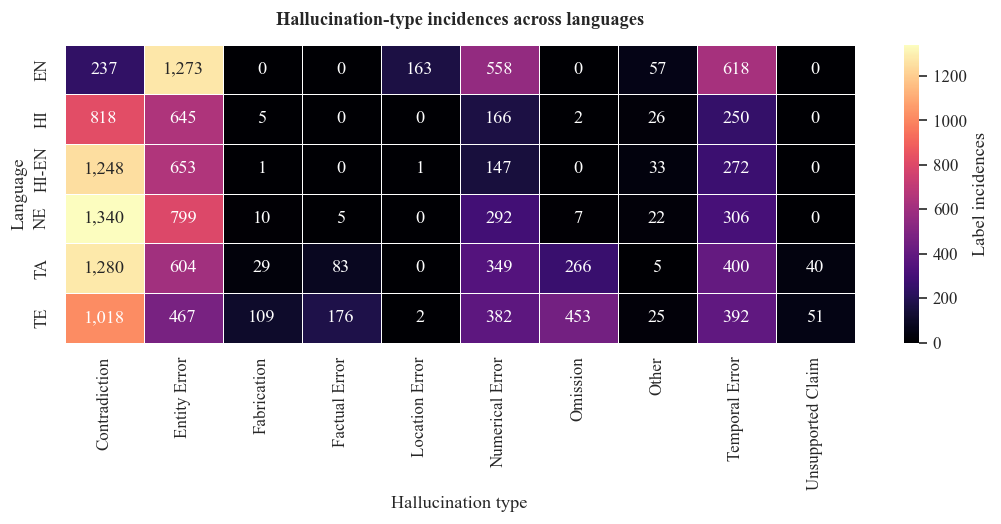

hallucination_type,Contradiction,Entity Error,Fabrication,Factual Error,Location Error,Numerical Error,Omission,Other,Temporal Error,Unsupported Claim
language,,,,,,,,,,
EN,237,1273,0,0,163,558,0,57,618,0
HI,818,645,5,0,0,166,2,26,250,0
HI-EN,1248,653,1,0,1,147,0,33,272,0
NE,1340,799,10,5,0,292,7,22,306,0
TA,1280,604,29,83,0,349,266,5,400,40
TE,1018,467,109,176,2,382,453,25,392,51


In [17]:
# 17. Figure 12 — Hallucination type by language (incidence counts)
if not hallucination_long.empty and lang_col:
    lang_lookup = clean_series(data[lang_col]).to_dict()
    hallucination_long["language"] = hallucination_long["row_index"].map(lang_lookup)
    tab = pd.crosstab(hallucination_long["language"],
                      hallucination_long["hallucination_type"])
    fig, ax = plt.subplots(figsize=(max(9, 0.75 * tab.shape[1]),
                                    max(4.5, 0.65 * tab.shape[0])))
    sns.heatmap(tab, annot=True, fmt=",", cmap="magma",
                linewidths=0.4, ax=ax,
                cbar_kws={"label": "Label incidences"})
    ax.set_title("Hallucination-type incidences across languages", pad=12)
    ax.set_xlabel("Hallucination type")
    ax.set_ylabel("Language")
    fig.tight_layout()
    save_figure(fig, "fig12_hallucination_type_by_language")
    display(tab)
else:
    print("Skipped: hallucination type data or language column unavailable.")


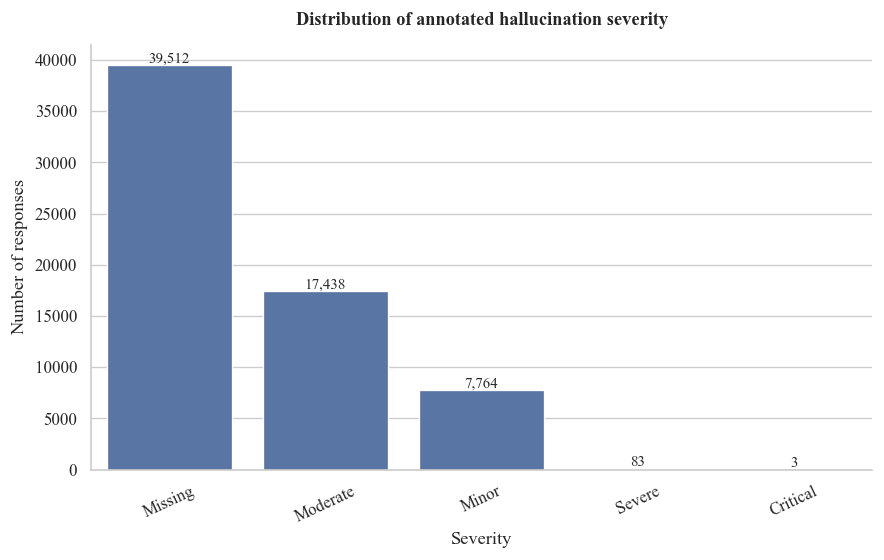

,responses
severity,
Missing,39512
Moderate,17438
Minor,7764
Severe,83
Critical,3


In [18]:
# 18. Figure 13 — Severity distribution
severity_col = COLS["severity"]
if severity_col:
    severity_counts = clean_series(data[severity_col]).value_counts()
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    sns.barplot(x=severity_counts.index, y=severity_counts.values, ax=ax)
    ax.set_title("Distribution of annotated hallucination severity", pad=12)
    ax.set_xlabel("Severity")
    ax.set_ylabel("Number of responses")
    ax.tick_params(axis="x", rotation=25)
    for i, v in enumerate(severity_counts.values):
        ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
    fig.tight_layout()
    save_figure(fig, "fig13_severity_distribution")
    display(severity_counts.rename("responses").to_frame())
else:
    print("Skipped: severity column not found.")


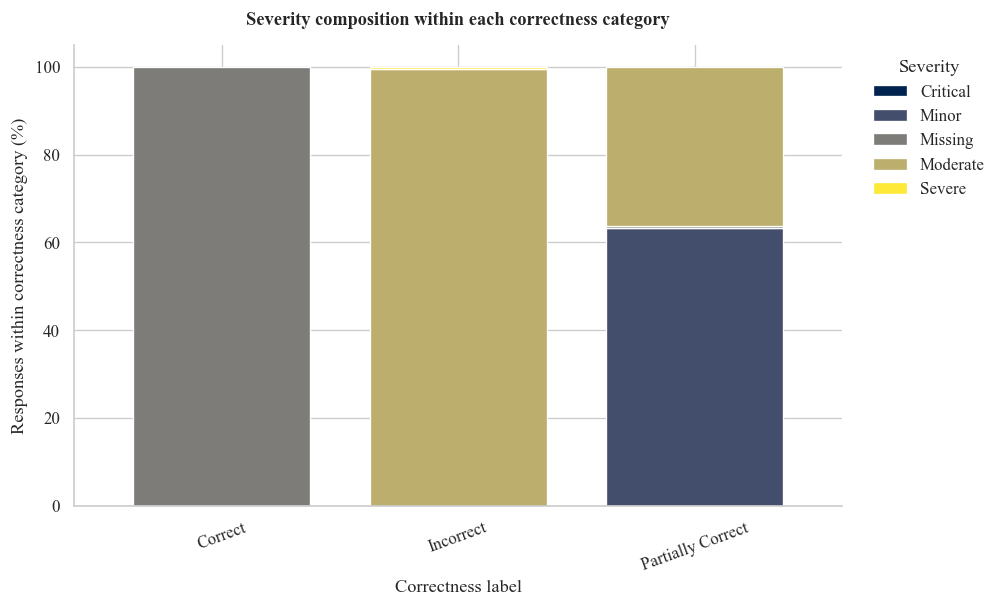

severity,Critical,Minor,Missing,Moderate,Severe
correctness_label,,,,,
Correct,0.00,0.00,100.00,0.00,0.00
Incorrect,0.02,0.00,0.01,99.34,0.63
Partially Correct,0.00,63.38,0.42,36.19,0.00


In [19]:
# 19. Figure 14 — Severity by correctness label
if severity_col and correct_col:
    tab = pd.crosstab(clean_series(data[correct_col]),
                      clean_series(data[severity_col]),
                      normalize="index") * 100
    fig, ax = plt.subplots(figsize=(8.5, 5.2))
    tab.plot(kind="bar", stacked=True, ax=ax, colormap="cividis", width=0.75)
    ax.set_title("Severity composition within each correctness category", pad=12)
    ax.set_xlabel("Correctness label")
    ax.set_ylabel("Responses within correctness category (%)")
    ax.legend(title="Severity", bbox_to_anchor=(1.02, 1), loc="upper left")
    ax.tick_params(axis="x", rotation=20)
    fig.tight_layout()
    save_figure(fig, "fig14_severity_by_correctness")
    display(tab.round(2))
else:
    print("Skipped: severity or correctness column not found.")


## D. Annotation provenance and review diagnostics

These plots are especially important for a mixed human/LLM-labelled dataset. They make the annotation source transparent and help identify where manual review was concentrated.


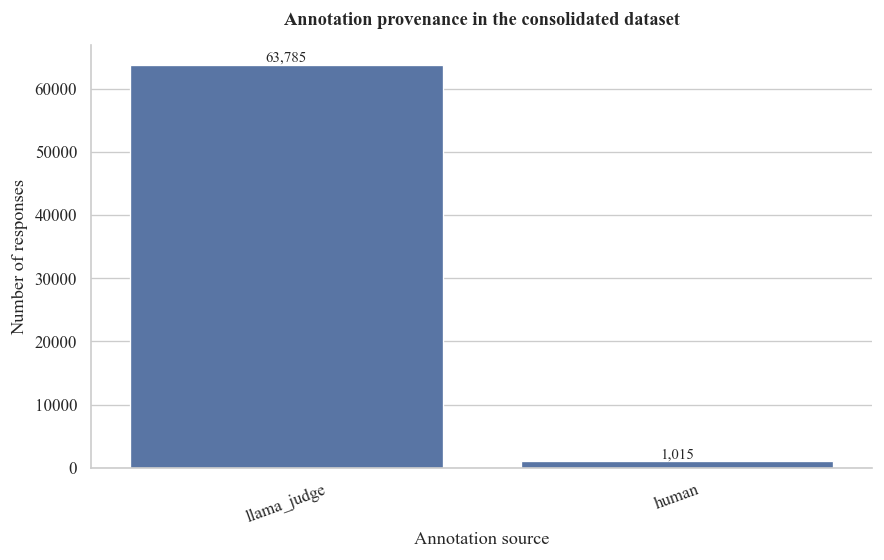

,responses
annotation_source,
llama_judge,63785
human,1015


In [20]:
# 20. Figure 15 — Annotation source distribution
source_col = COLS["source"]
if source_col:
    source_counts = clean_series(data[source_col]).value_counts()
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    sns.barplot(x=source_counts.index, y=source_counts.values, ax=ax)
    ax.set_title("Annotation provenance in the consolidated dataset", pad=12)
    ax.set_xlabel("Annotation source")
    ax.set_ylabel("Number of responses")
    ax.tick_params(axis="x", rotation=20)
    for i, v in enumerate(source_counts.values):
        ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
    fig.tight_layout()
    save_figure(fig, "fig15_annotation_provenance")
    display(source_counts.rename("responses").to_frame())
else:
    print("Skipped: annotation_source column not found.")


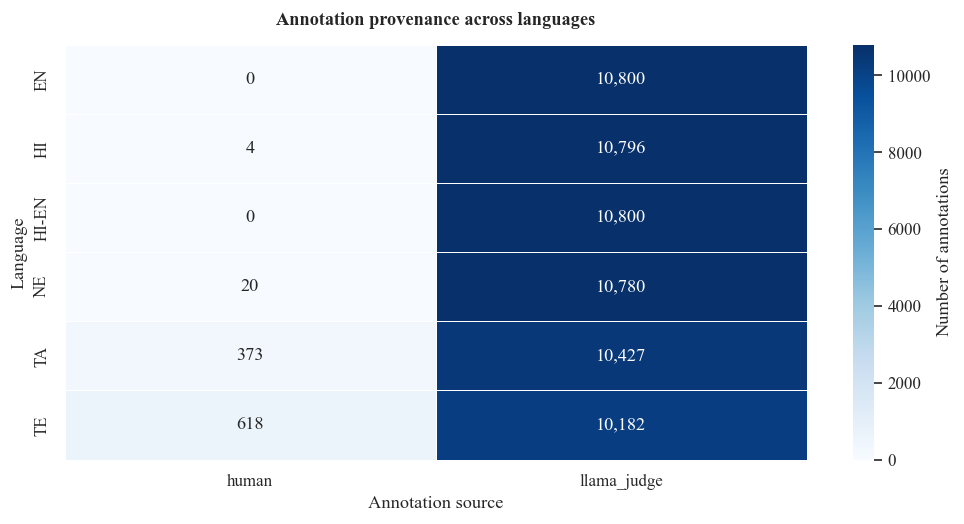

annotation_source,human,llama_judge
language,,
EN,0,10800
HI,4,10796
HI-EN,0,10800
NE,20,10780
TA,373,10427
TE,618,10182


In [21]:
# 21. Figure 16 — Annotation source by language
if source_col and lang_col:
    tab = pd.crosstab(clean_series(data[lang_col]),
                      clean_series(data[source_col]))
    fig, ax = plt.subplots(figsize=(8.5, max(4.5, 0.65 * len(tab))))
    sns.heatmap(tab, annot=True, fmt=",", cmap="Blues",
                linewidths=0.5, ax=ax,
                cbar_kws={"label": "Number of annotations"})
    ax.set_title("Annotation provenance across languages", pad=12)
    ax.set_xlabel("Annotation source")
    ax.set_ylabel("Language")
    fig.tight_layout()
    save_figure(fig, "fig16_provenance_by_language")
    display(tab)
else:
    print("Skipped: source or language column not found.")


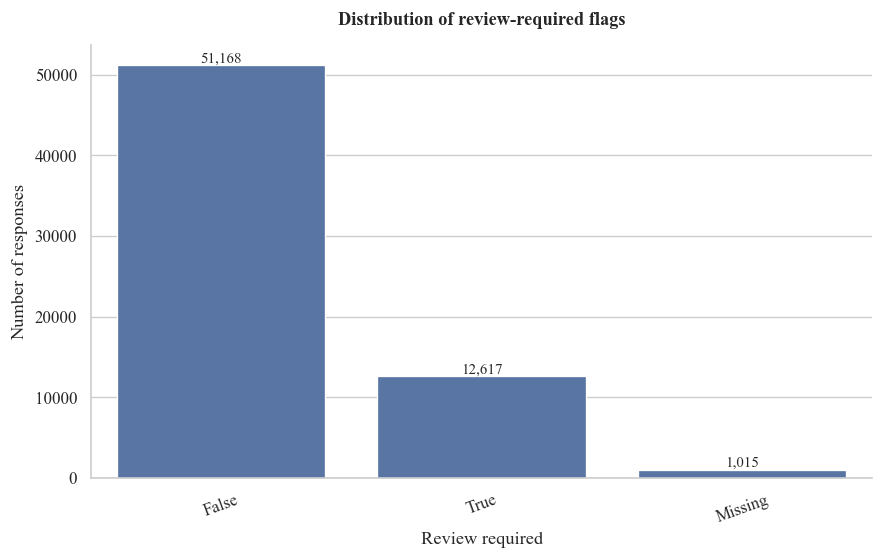

,responses
review_required,
False,51168
True,12617
Missing,1015


In [22]:
# 22. Figure 17 — Review-required distribution
review_col = COLS["review_required"]
if review_col:
    review_counts = clean_series(data[review_col]).value_counts()
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    sns.barplot(x=review_counts.index, y=review_counts.values, ax=ax)
    ax.set_title("Distribution of review-required flags", pad=12)
    ax.set_xlabel("Review required")
    ax.set_ylabel("Number of responses")
    ax.tick_params(axis="x", rotation=20)
    for i, v in enumerate(review_counts.values):
        ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
    fig.tight_layout()
    save_figure(fig, "fig17_review_required")
    display(review_counts.rename("responses").to_frame())
else:
    print("Skipped: review_required column not found.")


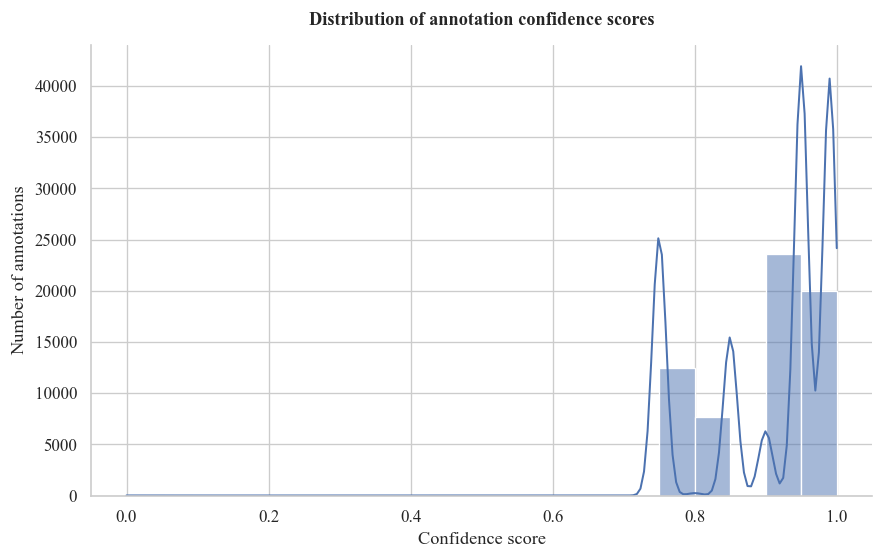

count    63785.000000
mean         0.908882
std          0.089450
min          0.000000
25%          0.850000
50%          0.950000
75%          0.990000
max          1.000000
Name: confidence, dtype: float64


In [23]:
# 23. Figure 18 — Confidence distribution (if numeric)
confidence_col = COLS["confidence"]
if confidence_col:
    confidence_values = pd.to_numeric(data[confidence_col], errors="coerce").dropna()
    if len(confidence_values):
        fig, ax = plt.subplots(figsize=(7.5, 4.8))
        sns.histplot(confidence_values, bins=20, kde=True, ax=ax)
        ax.set_title("Distribution of annotation confidence scores", pad=12)
        ax.set_xlabel("Confidence score")
        ax.set_ylabel("Number of annotations")
        fig.tight_layout()
        save_figure(fig, "fig18_confidence_distribution")
        print(confidence_values.describe())
    else:
        print("Confidence column exists but has no numeric values; inspect its scale/encoding.")
else:
    print("Skipped: confidence column not found.")


## E. Response-length and model/language diagnostics

Response length is a descriptive measure only. It must not be interpreted as a direct measure of correctness or hallucination.


In [24]:
# 24. Figure 19 — Response length by language
response_col = COLS["response"]
if response_col and lang_col:
    length_df = pd.DataFrame({
        "language": clean_series(data[lang_col]),
        "response_words": data[response_col].fillna("").astype(str).str.split().str.len()
    })
    # Exclude empty responses from the distribution
    length_df = length_df[length_df["response_words"] > 0]
    fig, ax = plt.subplots(figsize=(9, 5.5))
    sns.boxplot(data=length_df, x="language", y="response_words", ax=ax,
                showfliers=False)
    ax.set_title("Response-length distribution across languages", pad=12)
    ax.set_xlabel("Language")
    ax.set_ylabel("Response length (whitespace-delimited tokens)")
    ax.tick_params(axis="x", rotation=25)
    fig.tight_layout()
    save_figure(fig, "fig19_response_length_by_language")
    display(length_df.groupby("language")["response_words"].describe().round(2))
else:
    print("Skipped: response or language column not found.")


Skipped: response or language column not found.


In [25]:
# 25. Figure 20 — Response length by model
if response_col and model_col:
    length_df = pd.DataFrame({
        "model": clean_series(data[model_col]),
        "response_words": data[response_col].fillna("").astype(str).str.split().str.len()
    })
    length_df = length_df[length_df["response_words"] > 0]
    fig, ax = plt.subplots(figsize=(10, 5.5))
    sns.boxplot(data=length_df, x="model", y="response_words", ax=ax,
                showfliers=False)
    ax.set_title("Response-length distribution across evaluated models", pad=12)
    ax.set_xlabel("Model")
    ax.set_ylabel("Response length (whitespace-delimited tokens)")
    ax.tick_params(axis="x", rotation=30)
    fig.tight_layout()
    save_figure(fig, "fig20_response_length_by_model")
    display(length_df.groupby("model")["response_words"].describe().round(2))
else:
    print("Skipped: response or model column not found.")


Skipped: response or model column not found.


## F. Data integrity and reproducibility checks

Run these checks before using the figures in the manuscript. Any imbalance or missingness should be described rather than concealed.


In [26]:
# 26. Dataset integrity report
integrity = pd.DataFrame({
    "metric": [
        "Total rows",
        "Number of columns",
        "Unique response IDs",
        "Missing response IDs",
        "Duplicate response IDs",
        "Unique question IDs",
        "Missing question IDs",
    ],
    "value": [
        len(data),
        len(data.columns),
        data[COLS["response_id"]].nunique() if COLS["response_id"] else np.nan,
        data[COLS["response_id"]].isna().sum() if COLS["response_id"] else np.nan,
        data[COLS["response_id"]].duplicated().sum() if COLS["response_id"] else np.nan,
        data[COLS["question_id"]].nunique() if COLS["question_id"] else np.nan,
        data[COLS["question_id"]].isna().sum() if COLS["question_id"] else np.nan,
    ]
})
display(integrity)
integrity.to_csv(OUTPUT_DIR / "table_data_integrity.csv", index=False)

missingness = (
    data.isna().sum()
    .rename("missing_count")
    .to_frame()
    .assign(missing_percent=lambda x: 100 * x["missing_count"] / max(len(data), 1))
    .sort_values("missing_percent", ascending=False)
)
display(missingness)
missingness.to_csv(OUTPUT_DIR / "table_missingness.csv")


,metric,value
0,Total rows,64800
1,Number of columns,20
2,Unique response IDs,64800
3,Missing response IDs,0
4,Duplicate response IDs,0
5,Unique question IDs,10800
6,Missing question IDs,0


,missing_count,missing_percent
human_annotator,63785,98.433642
fact_id,54000,83.333333
severity,39512,60.975309
claims,1015,1.566358
annotator_model,1015,1.566358
judge_output_tokens,1015,1.566358
confidence,1015,1.566358
timestamp,1015,1.566358
review_required,1015,1.566358
judge_prompt_tokens,1015,1.566358


In [27]:
# 27. Cross-tabulation tables for manuscript reporting
tables = {}

for key_a, key_b, filename in [
    ("language", "model", "table_language_by_model.csv"),
    ("language", "correctness", "table_correctness_by_language.csv"),
    ("model", "correctness", "table_correctness_by_model.csv"),
    ("language", "source", "table_annotation_source_by_language.csv"),
    ("correctness", "severity", "table_correctness_by_severity.csv"),
]:
    col_a, col_b = COLS.get(key_a), COLS.get(key_b)
    if col_a and col_b:
        tab = pd.crosstab(clean_series(data[col_a]), clean_series(data[col_b]))
        tables[filename] = tab
        tab.to_csv(OUTPUT_DIR / filename)
        print("\n", filename)
        display(tab)

print("Cross-tabulation tables saved.")



 table_language_by_model.csv


model_name,Claude Sonnet 5.5,DeepSeek-V4.1-Flash,GLM-5.3 Flash,GPT-5.6 Luna,Gemini 3,Qwen 3.7
language,,,,,,
EN,1800,1800,1800,1800,1800,1800
HI,1800,1800,1800,1800,1800,1800
HI-EN,1800,1800,1800,1800,1800,1800
NE,1800,1800,1800,1800,1800,1800
TA,1800,1800,1800,1800,1800,1800
TE,1800,1800,1800,1800,1800,1800



 table_correctness_by_language.csv


correctness_label,Correct,Incorrect,Partially Correct
language,,,
EN,6901,1849,2050
HI,7104,1677,2019
HI-EN,5756,2103,2941
NE,6118,2582,2100
TA,6688,2575,1537
TE,6892,2306,1602



 table_correctness_by_model.csv


correctness_label,Correct,Incorrect,Partially Correct
model_name,,,
Claude Sonnet 5.5,6913,1679,2208
DeepSeek-V4.1-Flash,6485,2416,1899
GLM-5.3 Flash,7680,1298,1822
GPT-5.6 Luna,6438,2298,2064
Gemini 3,5919,2739,2142
Qwen 3.7,6024,2662,2114



 table_annotation_source_by_language.csv


annotation_source,human,llama_judge
language,,
EN,0,10800
HI,4,10796
HI-EN,0,10800
NE,20,10780
TA,373,10427
TE,618,10182



 table_correctness_by_severity.csv


severity,Critical,Minor,Missing,Moderate,Severe
correctness_label,,,,,
Correct,0,0,39459,0,0
Incorrect,3,0,1,13005,83
Partially Correct,0,7764,52,4433,0


Cross-tabulation tables saved.


In [28]:
# 28. Export a compact figure manifest
figure_files = sorted(
    p.name for p in OUTPUT_DIR.iterdir()
    if p.suffix.lower() in {".png", ".pdf", ".svg"}
)
manifest = pd.DataFrame({"figure_file": figure_files})
manifest.to_csv(OUTPUT_DIR / "figure_manifest.csv", index=False)

print(f"Figures created: {len(figure_files)} files (PNG/PDF/SVG versions)")
print(f"All outputs saved under: {OUTPUT_DIR.resolve()}")
display(manifest)


Figures created: 45 files (PNG/PDF/SVG versions)
All outputs saved under: C:\Users\CH.SC.U4CSE23160\Neural Project\IndicHallbench-Hallucinations-Benchmark\notebooks\results\publication_figures


,figure_file
0,fig01_language_distribution.pdf
1,fig01_language_distribution.png
2,fig01_language_distribution.svg
3,fig03_model_distribution.pdf
4,fig03_model_distribution.png
5,fig03_model_distribution.svg
6,fig04_language_model_coverage.pdf
7,fig04_language_model_coverage.png
8,fig04_language_model_coverage.svg
9,fig07_correctness_distribution.pdf


## Suggested figure selection for the main paper

Avoid placing every exploratory figure in the main manuscript. A concise main-paper selection could be:

1. **Dataset composition:** language × model coverage (Fig. 4).
2. **Benchmark composition:** domain and difficulty distributions (Figs. 2 and 5).
3. **Annotation outcome overview:** correctness distribution and correctness by language (Figs. 7 and 8).
4. **Error taxonomy:** hallucination-type frequency and type-by-language heatmap (Figs. 11 and 12).
5. **Annotation transparency:** provenance by language (Fig. 16), especially because the dataset combines LLM-judge and human annotations.

Move other figures and detailed tables to supplementary material if the journal's page limits require it.

**Manuscript caution:** These are descriptive dataset visualizations. They do not establish statistical significance, inter-annotator agreement, annotation validity, or comparative model performance. Those require separate analyses and, where appropriate, independent human labels and statistical tests.
